The VGG-16 architecture is a deep convolutional neural network (CNN) designed for image classification tasks. It was introduced by the Visual Geometry Group at the University of Oxford. VGG-16 is characterized by its simplicity and uniform architecture, making it easy to understand and implement.

The VGG-16 configuration typically consists of 16 layers, including 13 convolutional layers and 3 fully connected layers. These layers are organized into blocks, with each block containing multiple convolutional layers followed by a max-pooling layer for downsampling.

In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom
import matplotlib.pyplot as plt

In [ ]:
import tensorflow as tf

# Adjust GPU memory allocation to 8.4 GB
# Use this just for tensorflow on macOS
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_virtual_device_configuration(
                gpu,
                [tf.config.experimental.VirtualDeviceConfiguration(memory_limit=8400)]
            )
    except RuntimeError as e:
        print(e)

Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-04-02 19:06:25.190381: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-04-02 19:06:25.190412: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-04-02 19:06:25.190420: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-04-02 19:06:25.190437: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-04-02 19:06:25.190447: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Epoch 1/60


2025-04-02 19:06:26.623458: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


360/360 ━━━━━━━━━━━━━━━━━━━━ 159s 438ms/step - accuracy: 0.3181 - loss: 3.9838 - val_accuracy: 0.6419 - val_loss: 1.1388 - learning_rate: 1.0000e-04
Epoch 2/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 433ms/step - accuracy: 0.4842 - loss: 2.3984 - val_accuracy: 0.7398 - val_loss: 0.8986 - learning_rate: 1.0000e-04
Epoch 3/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 433ms/step - accuracy: 0.5648 - loss: 1.9183 - val_accuracy: 0.7641 - val_loss: 0.8157 - learning_rate: 1.0000e-04
Epoch 4/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 434ms/step - accuracy: 0.6186 - loss: 1.6240 - val_accuracy: 0.7862 - val_loss: 0.7440 - learning_rate: 1.0000e-04
Epoch 5/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 156s 433ms/step - accuracy: 0.6372 - loss: 1.4968 - val_accuracy: 0.7979 - val_loss: 0.6840 - learning_rate: 1.0000e-04
Epoch 6/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 155s 430ms/step - accuracy: 0.6663 - loss: 1.3251 - val_accuracy: 0.8099 - val_loss: 0.6567 - learning_rate: 1.0000e-04
Epoch 7/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 155s 430ms/

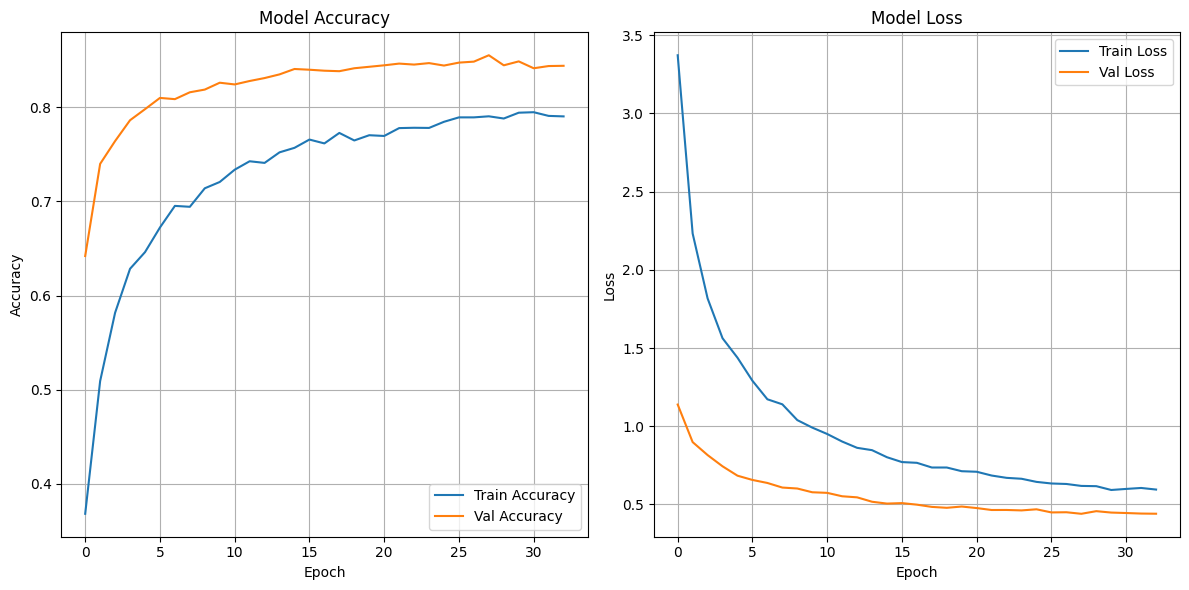

In [3]:
dataset_path = "../../../wheat_256px-dataset"
img_size = (256, 256)
batch_size = 32
num_classes = 5
seed = 42

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    color_mode="rgb",
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    color_mode="rgb",
    validation_split=0.4,
    subset="validation",
    seed=seed
)

val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
])

# === 4. Load VGG16 pretrained model (w/o top layers) ===
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
base_model.trainable = False  # Freeze the convolutional base initially

# === 5. Add classification head ===
inputs = tf.keras.Input(shape=(256, 256, 3))
x = data_augmentation(inputs)  # Apply augmentation
x = tf.keras.applications.vgg16.preprocess_input(x)  # Proper VGG16 preprocessing
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

# === 6. Compile with Lower Learning Rate ===
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Callbacks ===
callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_accuracy'),
    ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_accuracy'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=60,
    callbacks=callbacks
)

# === 9. Evaluation ===
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\nTest accuracy: {test_acc:.4f}")

# === 10. Plot Training Curves ===
plt.figure(figsize=(12, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


2025-04-02 21:21:12.251481: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


120/120 ━━━━━━━━━━━━━━━━━━━━ 37s 296ms/step

Classification Report:
              precision    recall  f1-score   support

  brown_rust       0.80      0.89      0.84       497
     healthy       0.82      0.86      0.84       442
      mildew       0.89      0.77      0.82       597
    septoria       0.92      0.88      0.89      1396
 yellow_rust       0.79      0.85      0.82       891

    accuracy                           0.85      3823
   macro avg       0.84      0.85      0.84      3823
weighted avg       0.85      0.85      0.85      3823


Additional Metrics:
Accuracy: 85.12%
Precision: 85.49%
Recall: 85.12%
F1-Score: 85.16%


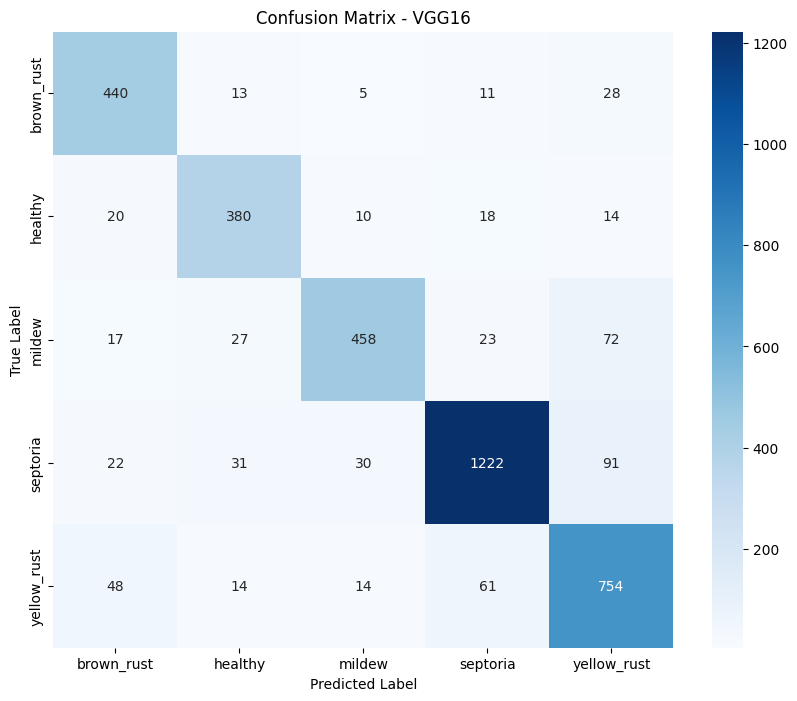

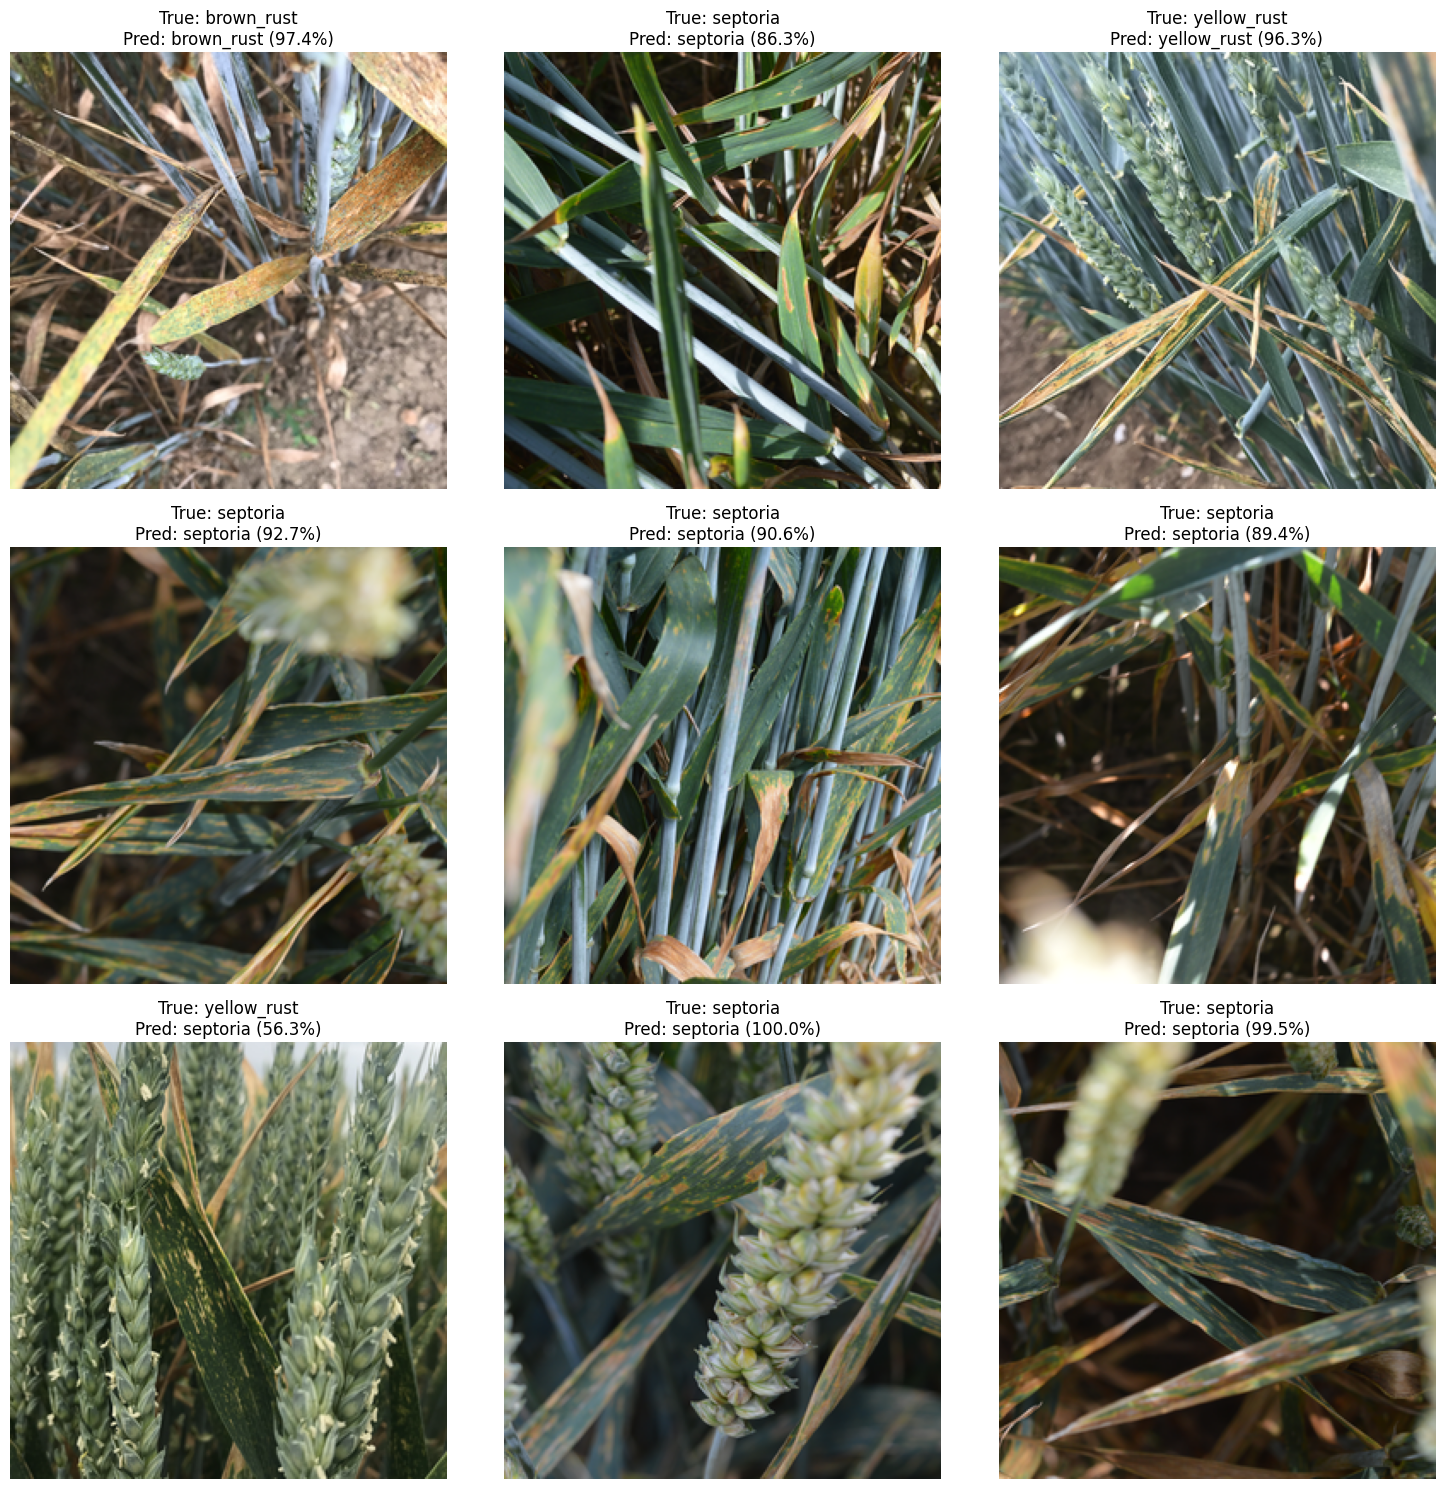

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

model = tf.keras.models.load_model('best_model.keras')
class_names = train_dataset.class_names

test_images, test_labels = [], []
for img, lbl in test_dataset.unbatch():
    test_images.append(img.numpy())
    test_labels.append(lbl.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

# predictions
predictions = model.predict(test_images, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

# metrics
accuracy = accuracy_score(test_labels, predicted_labels)
precision = precision_score(test_labels, predicted_labels, average='weighted')
recall = recall_score(test_labels, predicted_labels, average='weighted')
f1 = f1_score(test_labels, predicted_labels, average='weighted')

print("\nClassification Report:")
print(classification_report(test_labels, predicted_labels, target_names=class_names))

print("\nAdditional Metrics:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")

plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, predicted_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - VGG16')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

plt.figure(figsize=(15, 15))
for i in range(9):  # Show 9 random samples
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(test_images[i].astype('uint8'))  # Assumes RGB images
    true_label = class_names[test_labels[i]]
    pred_label = class_names[predicted_labels[i]]
    confidence = np.max(predictions[i]) * 100
    plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)")
    plt.axis('off')
plt.tight_layout()
plt.show()